# 1. Business problem

Dự đoán số phút kỹ thuật chủ động cho một công việc sửa chữa Apple.
**EXPERIMENTAL — SYNTHETIC-DATA TRAINED — NOT PRODUCTION VALIDATED.**
Prediction này là đầu vào tiềm năng của ETA, không phải ETA trực tiếp.

## 2. Regression formulation

Với tập $D=\{(x_i,y_i)\}_{i=1}^{n}$, mô hình học hàm
$\hat y_i=f(x_i)$ và tối ưu sai số trên biến liên tục phút kỹ thuật.
Đây không phải classification; không dùng accuracy, F1, ROC-AUC.

## 3. Target formula

$$y=\frac{1}{60}\sum_{k:s_k\in\{INSPECTING,REPAIRING\}}
\max(0,\min(e_k,a_e)-\max(b_k,a_s))_{seconds}.$$

Mỗi active status interval $[b_k,e_k)$ được giao với assignment $[a_s,a_e)$.
Queue, chờ duyệt, chờ linh kiện, break, transfer gap và chờ bàn giao bị loại.
Production duration hiện chưa tự trừ service interruptions; V3 giữ đúng giới hạn đó.

## 4. Prediction timestamp

Prediction timestamp là thời điểm assignment duy nhất sau khi phương án một
hạng mục APPROVED đã biết. Mọi feature phải tồn tại tại hoặc trước mốc này.

## 5. Sample grain

Một ticket hoàn tất, đúng một approved repair item, một concrete catalog item,
một ended assignment, không accepted transfer, ordered history đầy đủ và target
dương. Không phân bổ giả duration của ticket nhiều item.

## 6. Warranty context khác technical action

V3 dùng technical_action chỉ REPAIR hoặc REPLACEMENT. is_warranty là cờ ngữ
cảnh. Production derive cờ này từ warranty_source_item_id và resolve action từ
warranty_remedy hoặc catalog kỹ thuật thực thi. Legacy service type WARRANTY
không được coi là action thứ ba trong ML.

## 7. Feature contract V3

20 feature gồm 9 categorical và 11 numeric. History có ba tầng: toàn bộ KTV,
KTV×issue và KTV×exact catalog. Count cold start bằng 0; average/efficiency giữ
NaN, không bịa thành standard hoặc 1.0.

## 8. Leakage rules

Điều kiện duy nhất để một job cũ vào history:
previous_job.completed_at < current_prediction_timestamp.
Job bắt đầu trước nhưng hoàn tất sau bị loại. Preprocessing được fit trong từng
temporal fold; không backfill từ tương lai.

## 9. Synthetic limitations

Catalog, KTV và target đều là dữ liệu tổng hợp có kiểm soát. Hidden capability,
specialty, complexity, noise và outlier không xuất ra. is_warranty không có
hidden duration multiplier. Metric synthetic không phải độ chính xác thực tế.

## 10. Dataset validation

In [1]:
%matplotlib inline
from pathlib import Path
import platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, catboost

ML_ROOT = Path('ml') if Path('ml').exists() else Path.cwd()
sys.path.insert(0, str((ML_ROOT / 'src').resolve()))
from repair_duration_ml_v3.config import *
from repair_duration_ml_v3.data import load_dataset, temporal_holdout_split, feature_target
from repair_duration_ml_v3.training import run_competition

frame = load_dataset(ML_ROOT / 'data' / 'synthetic_repair_duration_v3.csv')
{
    'versions': {
        'python': platform.python_version(), 'sklearn': sklearn.__version__,
        'xgboost': xgboost.__version__, 'catboost': catboost.__version__,
    },
    'seed': SEED, 'shape': frame.shape,
    'duplicates': int(frame.duplicated().sum()),
    'missing': frame.isna().sum()[frame.isna().sum().gt(0)].to_dict(),
    'actions': frame.technical_action.value_counts().to_dict(),
    'warranty': frame.is_warranty.value_counts().to_dict(),
}

{'versions': {'python': '3.13.6',
  'sklearn': '1.8.0',
  'xgboost': '3.2.0',
  'catboost': '1.2.8'},
 'seed': 20261006,
 'shape': (5000, 24),
 'duplicates': 0,
 'missing': {'technician_average_duration_before': 17,
  'technician_historical_efficiency_before': 17,
  'technician_issue_average_duration_before': 152,
  'technician_issue_efficiency_before': 152,
  'technician_catalog_average_duration_before': 449,
  'technician_catalog_efficiency_before': 449},
 'actions': {'REPLACEMENT': 3645, 'REPAIR': 1355},
 'warranty': {0: 4433, 1: 567}}

## 11. Temporal split

In [2]:
split = temporal_holdout_split(frame)
X_dev, y_dev = feature_target(split.development)
X_test, y_test = feature_target(split.test)
{
    'development': [len(X_dev), split.development.prediction_timestamp.min(),
                    split.development.prediction_timestamp.max()],
    'holdout': [len(X_test), split.test.prediction_timestamp.min(),
                split.test.prediction_timestamp.max()],
}

{'development': [4250,
  Timestamp('2025-01-02 08:17:00'),
  Timestamp('2026-06-29 09:10:00')],
 'holdout': [750,
  Timestamp('2026-06-29 09:24:00'),
  Timestamp('2026-09-30 17:45:00')]}

## 12. Train-only EDA

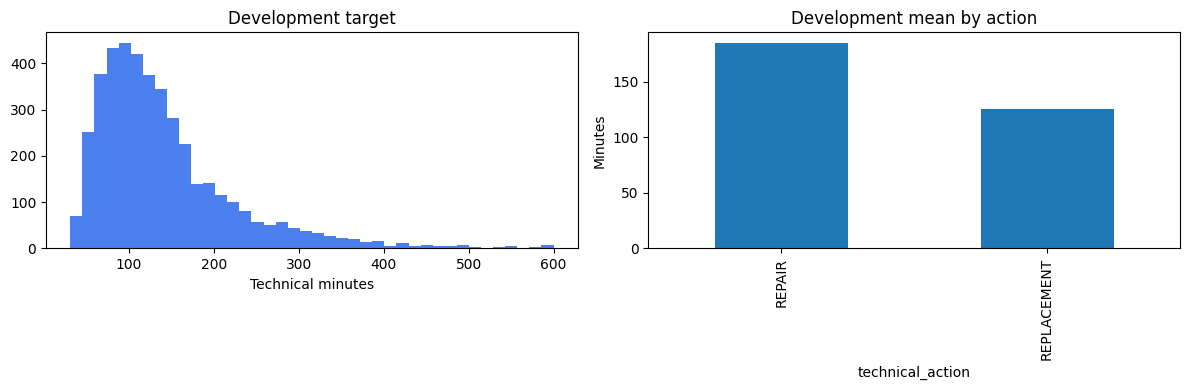

count    4250.00
mean      142.12
std        82.72
min        31.00
50%       121.00
90%       249.10
95%       311.00
max       600.00
Name: actual_technical_minutes, dtype: float64

In [3]:
eda = split.development
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eda[TARGET], bins=40, color='#2563eb', alpha=.82)
axes[0].set(title='Development target', xlabel='Technical minutes')
eda.groupby('technical_action', observed=True)[TARGET].mean().plot.bar(ax=axes[1])
axes[1].set(title='Development mean by action', ylabel='Minutes')
plt.tight_layout(); plt.show()
eda[TARGET].describe(percentiles=[.5,.9,.95]).round(2)

## 13. Baselines

Mean baseline dự đoán $\bar y_{train}$ trong mỗi fold.
StandardDurationBaseline dự đoán
$\hat y_i=standard\_duration\_minutes_i$ và là business baseline chính.

## 14. Metric formulas

$$MAE=\frac1n\sum|y_i-\hat y_i|,\quad
MSE=\frac1n\sum(y_i-\hat y_i)^2,\quad RMSE=\sqrt{MSE}.$$
$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$
$P90AE=Q_{0.90}(|y-\hat y|)$.
Within-$t=100\,n^{-1}\sum\mathbf1(|y_i-\hat y_i|\le t)$ với
$t\in\{15,30,45\}$ phút. Đây là tolerance, không phải classification accuracy.

## 15. Random Forest theory

$$\hat y_{RF}(x)=\frac1B\sum_{b=1}^{B}T_b(x).$$
Bootstrap, random feature subsets và averaging giảm variance; mỗi regression
split giảm tổng squared error của hai nút con.

## 16. HistGradientBoosting theory

$$F_m(x)=F_{m-1}(x)+\eta h_m(x).$$
Learner mới xấp xỉ negative gradient; histogram binning tăng hiệu quả tìm split.
Pipeline V3 dùng dense ordinal categories và native categorical splits.

## 17. XGBoost theory

$$Obj^{(t)}\approx\sum_i[g_if_t(x_i)+\tfrac12h_if_t(x_i)^2]+\Omega(f_t),$$
$$g_i=\partial_{\hat y}l,\quad h_i=\partial_{\hat y}^2l,\quad
\Omega(f)=\gamma T+\tfrac12\lambda\|w\|^2.$$

V3 dùng objective reg:squarederror để gradient/Hessian bậc hai khớp công thức;
eval_metric và model selection vẫn là MAE.

## 18. CatBoost theory

CatBoost xử lý category native và ordered target statistics. Minh họa:
$$TS_i=\frac{\sum_{\sigma(j)<\sigma(i)}1[x_j=x_i]y_j+aP}
{\sum_{\sigma(j)<\sigma(i)}1[x_j=x_i]+a}.$$
Permutation order giúp không dùng target hiện tại để encode chính nó. Đây là
trực giác rút gọn, không phải toàn bộ thuật toán.

## 19. Hyperparameter tuning

Bốn candidate dùng cùng TimeSeriesSplit(4), RandomizedSearchCV fixed seed,
12 cấu hình/model và neg_mean_absolute_error. RF/HGB/XGB/CatBoost giữ
preprocessing phù hợp riêng; không StandardScaler không cần thiết.

## 20. Temporal CV comparison

In [4]:
result = run_competition(
    ML_ROOT / 'data' / 'synthetic_repair_duration_v3.csv',
    output_dir=None, cv_splits=4, test_fraction=.15,
    search_iterations=12, smoke=False,
)
cv_columns = [
    'model','cv_mae_mean','cv_mae_std','cv_mse','cv_rmse','cv_r2',
    'cv_p90_absolute_error','cv_within_15_percent',
    'cv_within_30_percent','cv_within_45_percent'
]
result.cv_table[cv_columns].round(3)

,model,cv_mae_mean,cv_mae_std,cv_mse,cv_rmse,cv_r2,cv_p90_absolute_error,cv_within_15_percent,cv_within_30_percent,cv_within_45_percent
0,HistGradientBoostingRegressor,31.081,3.310,2300.051,47.727,0.668,64.611,38.618,64.794,79.618
1,CatBoostRegressor,31.192,2.522,2130.387,46.016,0.692,64.690,35.882,63.176,79.412
2,XGBRegressor,31.227,1.977,2161.967,46.381,0.687,65.773,36.176,63.294,79.176
3,RandomForestRegressor,31.264,2.045,2153.154,46.302,0.688,65.712,36.735,62.941,79.294
4,StandardDurationBaseline,37.249,3.753,3499.446,58.978,0.495,85.050,37.471,60.765,75.000
5,MeanBaseline,61.037,1.135,6954.230,83.356,-0.009,110.714,15.294,30.529,45.176


## 21. Winner lock

In [5]:
{'winner': result.winner_name, 'reason': result.winner_reason,
 'best_parameters': result.best_parameters[result.winner_name]}

{'winner': 'XGBRegressor',
 'reason': 'Models within 0.25 minute of the best CV MAE were treated as a practical tie (HistGradientBoostingRegressor, CatBoostRegressor, XGBRegressor, RandomForestRegressor). XGBRegressor was locked using, in order, lower CV-MAE standard deviation, CV RMSE, CV P90 absolute error and implementation-complexity rank. The test set was not consulted.',
 'best_parameters': {'model__subsample': 1.0,
  'model__reg_lambda': 8.0,
  'model__reg_alpha': 0.0,
  'model__n_estimators': 160,
  'model__min_child_weight': 1,
  'model__max_depth': 3,
  'model__learning_rate': 0.05,
  'model__colsample_bytree': 0.75}}

## 22. Final holdout

Holdout 15% cuối chỉ được đánh giá bên trong reusable core sau khi winner đã
khóa bằng development CV. Bảng vẫn hiển thị mọi candidate để audit; không đổi
winner theo kết quả holdout.

In [6]:
test_columns = [
    'model','mae','mse','rmse','r2','p90_absolute_error',
    'within_15_percent','within_30_percent','within_45_percent',
    'fit_seconds','predict_seconds'
]
result.test_table[test_columns].round(3)

,model,mae,mse,rmse,r2,p90_absolute_error,within_15_percent,within_30_percent,within_45_percent,fit_seconds,predict_seconds
0,HistGradientBoostingRegressor,27.928,1730.849,41.603,0.739,56.805,38.267,67.200,81.867,0.705,0.040
1,CatBoostRegressor,29.021,1802.129,42.451,0.728,60.860,37.733,67.067,81.733,7.069,0.007
2,RandomForestRegressor,29.274,1793.112,42.345,0.729,60.059,36.133,64.267,81.200,7.381,0.036
3,XGBRegressor,29.457,1834.091,42.826,0.723,61.014,34.933,64.933,81.200,0.158,0.026
4,StandardDurationBaseline,34.788,2933.591,54.163,0.557,79.000,38.933,62.267,75.467,0.000,0.000
5,MeanBaseline,60.152,6646.059,81.523,-0.004,105.124,13.733,30.267,45.467,0.000,0.000


## 23. Residual diagnostics

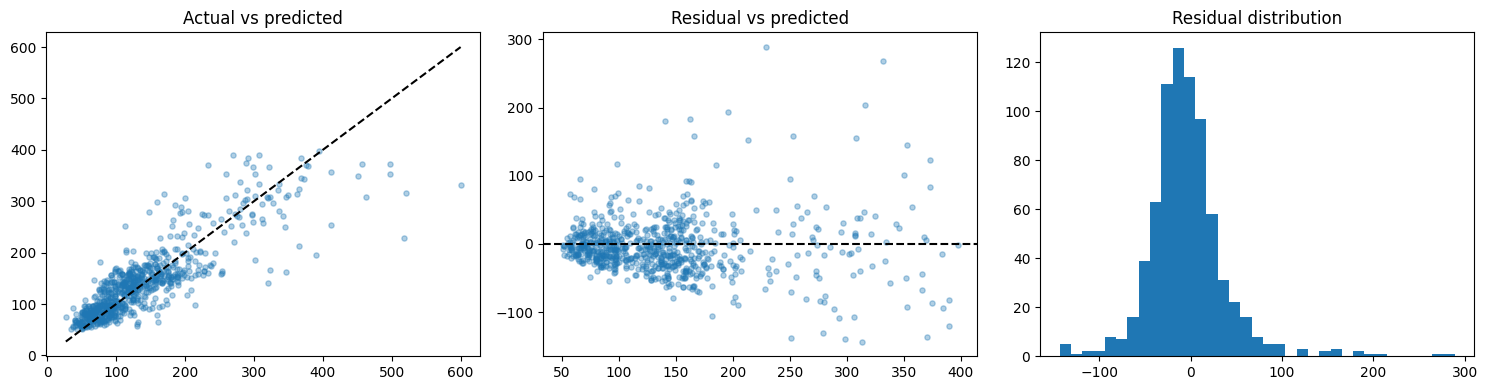

count    750.000
mean      -3.964
std       42.671
min     -143.173
25%      -26.783
50%       -8.086
75%       13.930
max      288.756
dtype: float64

In [7]:
residual = y_test.to_numpy() - result.test_predictions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y_test, result.test_predictions, alpha=.35, s=14)
lo=min(y_test.min(),result.test_predictions.min()); hi=max(y_test.max(),result.test_predictions.max())
axes[0].plot([lo,hi],[lo,hi],'k--'); axes[0].set(title='Actual vs predicted')
axes[1].scatter(result.test_predictions,residual,alpha=.35,s=14)
axes[1].axhline(0,color='k',ls='--'); axes[1].set(title='Residual vs predicted')
axes[2].hist(residual,bins=35); axes[2].set(title='Residual distribution')
plt.tight_layout(); plt.show()
pd.Series(residual).describe().round(3)

## 24. Tolerance metrics

In [8]:
winner_test = result.test_table[result.test_table.model.eq(result.winner_name)].iloc[0]
winner_test[['p90_absolute_error','within_15_percent',
             'within_30_percent','within_45_percent']].round(3)

p90_absolute_error    61.014
within_15_percent     34.933
within_30_percent     64.933
within_45_percent       81.2
Name: 3, dtype: object

## 25. Subgroup analysis

In [9]:
{name: pd.DataFrame(rows) for name, rows in result.subgroup_metrics.items()}

{'technician_id':       group  sample_count        mae       rmse
 0   TECH_11            79  39.110376  58.309154
 1   TECH_09            54  35.556949  50.170389
 2   TECH_12            52  34.347931  49.568810
 3   TECH_01            72  31.358898  47.591175
 4   TECH_02            68  30.740059  39.561962
 5   TECH_04            66  29.506892  41.621289
 6   TECH_06            58  27.423493  35.954802
 7   TECH_10            66  25.875668  34.468830
 8   TECH_05            73  25.558679  42.243017
 9   TECH_07            71  25.393552  33.008369
 10  TECH_03            40  24.899691  35.922507
 11  TECH_08            51  20.357595  30.295542,
 'device_type':          group  sample_count        mae       rmse
 0      MacBook           118  45.265984  61.771501
 1         iPad           106  34.887377  46.181662
 2      AirPods            68  27.973474  37.874434
 3  Apple Watch            77  25.222731  36.625157
 4       iPhone           381  24.170655  36.168557,
 'service_issue':

## 26. Feature importance

Permutation importance đo MAE tăng khi xáo trộn một feature trên holdout.
Đây là giá trị dự báo đối với model, không chứng minh quan hệ nhân quả.

In [10]:
pd.DataFrame(result.feature_importances).head(20).round(4)

,feature,importance_mean_mae_increase,importance_std
0,standard_duration_minutes,29.1427,1.0850
1,technician_issue_average_duration_before,1.3900,0.1431
2,technician_catalog_average_duration_before,1.0697,0.0959
3,service_issue,0.8043,0.0776
4,branch_id,0.3931,0.0945
5,technician_issue_efficiency_before,0.3834,0.0661
6,technician_historical_efficiency_before,0.3665,0.1424
7,device_type,0.1685,0.0548
8,technician_issue_jobs_before,0.1346,0.1021
9,technician_catalog_efficiency_before,0.1265,0.0990


## 27. Cold start

In [11]:
pd.Series(result.cold_start_predictions, name='predicted_technical_minutes')

known_history                   92.533089
new_technician                  97.773445
overall_but_no_issue_history    97.417221
issue_but_no_catalog_history    95.106827
unseen_categories               98.806938
Name: predicted_technical_minutes, dtype: float64

## 28. New-job prediction example

In [12]:
from repair_duration_ml_v3.evaluation import cold_start_examples
example = cold_start_examples(X_dev).loc[['new_technician']]
{'features': example.to_dict(orient='records')[0],
 'prediction': float(result.winner_estimator.predict(example)[0])}

{'features': {'device_type': 'iPhone',
  'device_model': 'iPhone 16 Pro',
  'service_issue': 'Pin',
  'technical_action': 'REPLACEMENT',
  'is_warranty': 0,
  'catalog_service': 'Thay pin iPhone 16 Pro',
  'standard_duration_minutes': 75,
  'technician_id': 'TECH_NEW',
  'branch_id': 'BRANCH_02',
  'prediction_month': 'M06',
  'prediction_weekday': 'MON',
  'technician_jobs_completed_before': 0,
  'technician_average_duration_before': nan,
  'technician_historical_efficiency_before': nan,
  'technician_issue_jobs_before': 0,
  'technician_issue_average_duration_before': nan,
  'technician_issue_efficiency_before': nan,
  'technician_catalog_jobs_before': 0,
  'technician_catalog_average_duration_before': nan,
  'technician_catalog_efficiency_before': nan},
 'prediction': 97.77344512939453}

## 29. Predicted duration và ETA

Predicted technical minutes chỉ mô tả active work. ETA tương lai phải kết hợp
queue, working schedule, configured break, current ticket state và operational
timing rules. Model không tự assign KTV và chưa được Spring Boot gọi.

## 30. Limitations

- synthetic data không xác nhận real-world generalization;
- multi-item, transfer và incomplete history bị loại;
- production interruption chưa bị duration service trừ;
- subgroup nhỏ phải đọc cùng sample count;
- permutation importance không phải causality;
- không có drift/backtest trên dữ liệu thật.

## 31. Next real-data phase

MySQL consistent snapshot → leakage-safe extractor → cùng V3 feature contract →
real temporal validation → explicit model approval → mới cân nhắc runtime/ETA
integration. Không có satisfaction classifier hoặc automatic retraining.